<center><h1>Lin_Juifan_HW5</h1></center>
<br>
<br>

Name: Juifan Lin
<br>
Github Username: JiaLiiin
<br>
USC ID: 9985422205

## 1. Decision Trees as Interpretable Models

Import packages

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
import xgboost as xgb


### (a) Obtain Data

Get the Accute Inamations Data Set

In [4]:
data_dir = os.path.join("..", "Data", "Homework 5 Data")
acute_path = os.path.join(data_dir, "diagnosis.data")
if not os.path.exists(acute_path):
    acute_path = os.path.join(data_dir, "diagnosis.csv")

acute_cols = [
    "temperature", "nausea", "lumbar_pain", 
    "urine_pushing", "micturition_pains", "burning_urethra", 
    "inflammation_urinary_bladder", "nephritis_renal_pelvis"
]

try:
    df_acute = pd.read_csv(acute_path, sep=r'\s+', encoding='utf-16', header=None, names=acute_cols, decimal=',')
except UnicodeError:
    df_acute = pd.read_csv(acute_path, sep=r'\s+', encoding='utf-8', header=None, names=acute_cols, decimal=',')

for c in acute_cols[1:]:
    df_acute[c] = df_acute[c].map({'yes': 1, 'no': 0})

df_acute['temperature'] = df_acute['temperature'].astype(float)

X_acute = df_acute.iloc[:, :6]
y_acute_powerset = (df_acute['inflammation_urinary_bladder'] * 2 + df_acute['nephritis_renal_pelvis']).values

class_names = [
    "None (0,0)", 
    "Nephritis only (0,1)", 
    "Bladder only (1,0)", 
    "Both (1,1)"
]


### (b) Build a decision tree

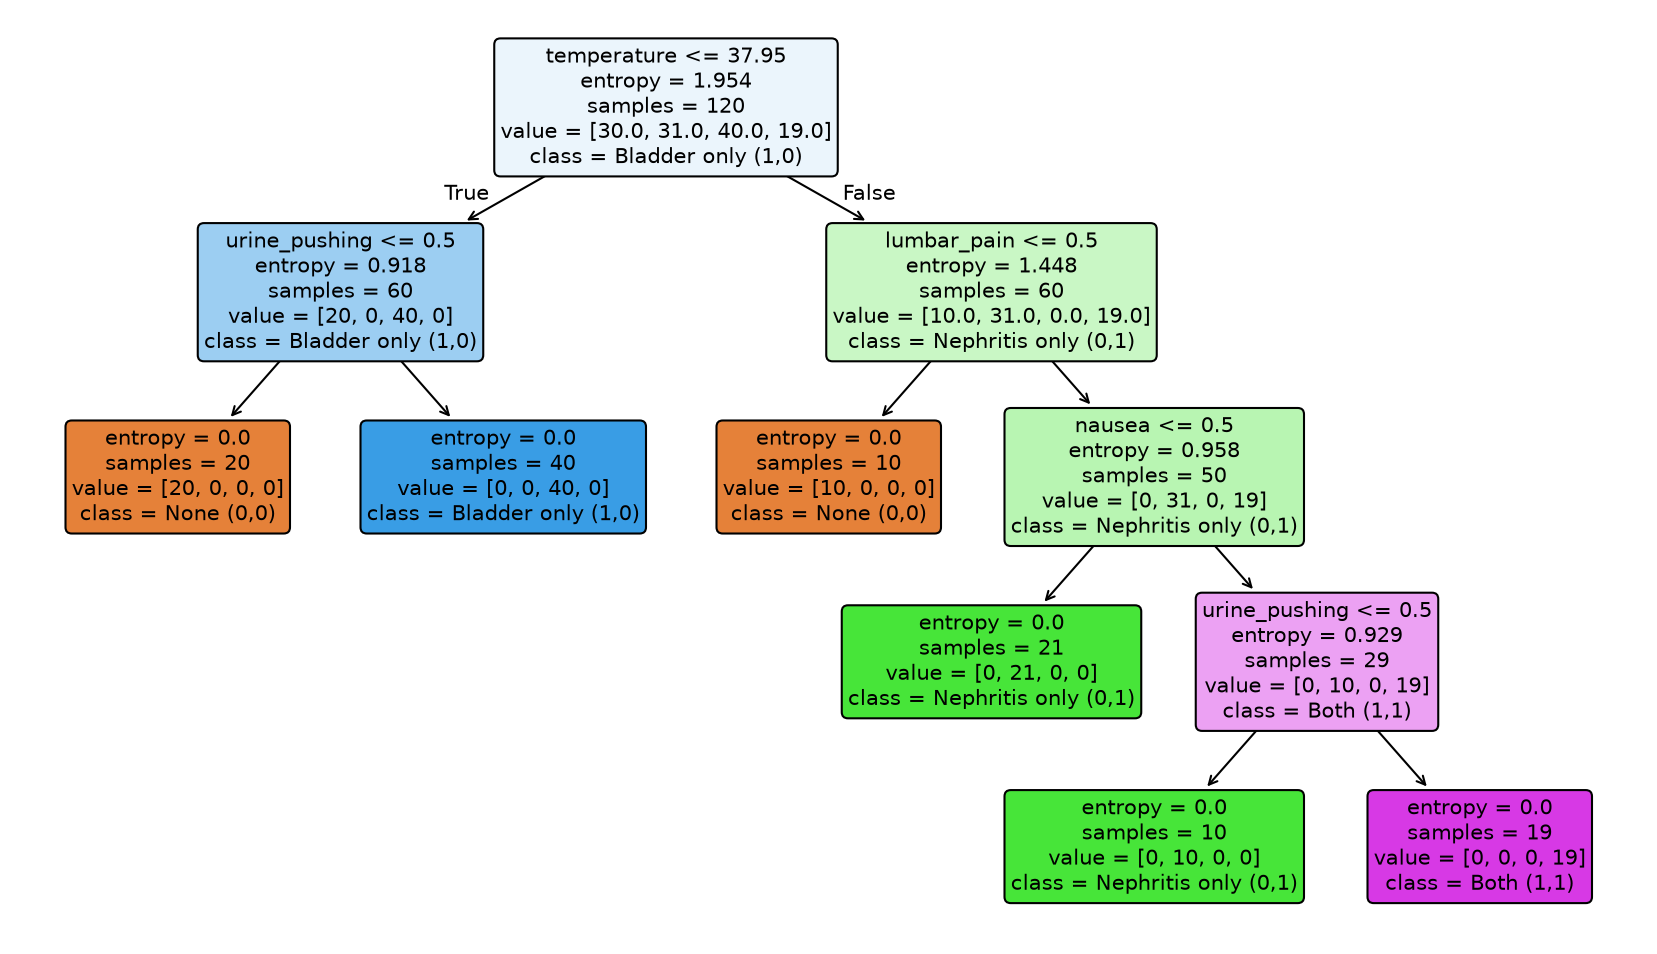

In [6]:
dt_acute = DecisionTreeClassifier(criterion='entropy', random_state=42)
dt_acute.fit(X_acute, y_acute_powerset)

plt.figure(figsize=(14, 8), dpi=150)
plot_tree(
    dt_acute, 
    feature_names=X_acute.columns, 
    class_names=class_names, 
    filled=True, 
    rounded=True, 
    fontsize=10
)
plt.show()

### (c) Convert the decision rules

In [ ]:
def get_rules(tree, feature_names, class_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != -2 else "undefined!"
        for i in tree_.feature
    ]
    
    rules = []
    def recurse(node, rule):
        if tree_.feature[node] != -2:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            recurse(tree_.children_left[node], rule + [f"({name} <= {threshold:.2f})"])
            recurse(tree_.children_right[node], rule + [f"({name} > {threshold:.2f})"])
        else:
            predicted_class = class_names[np.argmax(tree_.value[node])]
            rules.append("IF " + " AND ".join(rule) + f" THEN Class = {predicted_class}")
    recurse(0, [])
    return rules

rules = get_rules(dt_acute, X_acute.columns, class_names)
for r in rules:
    print(r)

IF (temperature <= 37.95) AND (urine_pushing <= 0.50) THEN Class = None (0,0)
IF (temperature <= 37.95) AND (urine_pushing > 0.50) THEN Class = Bladder only (1,0)
IF (temperature > 37.95) AND (lumbar_pain <= 0.50) THEN Class = None (0,0)
IF (temperature > 37.95) AND (lumbar_pain > 0.50) AND (nausea <= 0.50) THEN Class = Nephritis only (0,1)
IF (temperature > 37.95) AND (lumbar_pain > 0.50) AND (nausea > 0.50) AND (urine_pushing <= 0.50) THEN Class = Nephritis only (0,1)
IF (temperature > 37.95) AND (lumbar_pain > 0.50) AND (nausea > 0.50) AND (urine_pushing > 0.50) THEN Class = Both (1,1)


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [10]:
crime_names_path = os.path.join(data_dir, "communities.names")
crime_data_path = os.path.join(data_dir, "communities.data")
if not os.path.exists(crime_data_path):
    crime_data_path = os.path.join(data_dir, "communities.csv")

col_names = []
with open(crime_names_path, "r", encoding="utf-8", errors="ignore") as f:
    for line in f:
        if line.startswith("@attribute"):
            col_names.append(line.split()[1])

df_crime = pd.read_csv(crime_data_path, header=None, names=col_names, na_values="?")

train_raw = df_crime.iloc[:1495, :].copy()
test_raw = df_crime.iloc[1495:, :].copy()

### (b) Missing values

In [11]:
non_predictive = ['state', 'county', 'community', 'communityname', 'fold']
train = train_raw.drop(columns=[col for col in non_predictive if col in train_raw.columns])
test = test_raw.drop(columns=[col for col in non_predictive if col in test_raw.columns])

na_thresh = 0.8 * len(train)
cols_to_keep = train.columns[train.isna().sum() < na_thresh]
train = train[cols_to_keep]
test = test[cols_to_keep]

target_col = 'ViolentCrimesPerPop'
X_train_raw = train.drop(columns=[target_col])
y_train = train[target_col].values
X_test_raw = test.drop(columns=[target_col])
y_test = test[target_col].values

imputer = SimpleImputer(strategy='mean')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns)
print(f"Features after cleaning and imputation: {X_train.shape[1]}")

Features after cleaning and imputation: 100


### (c) Plot a correlation matrix

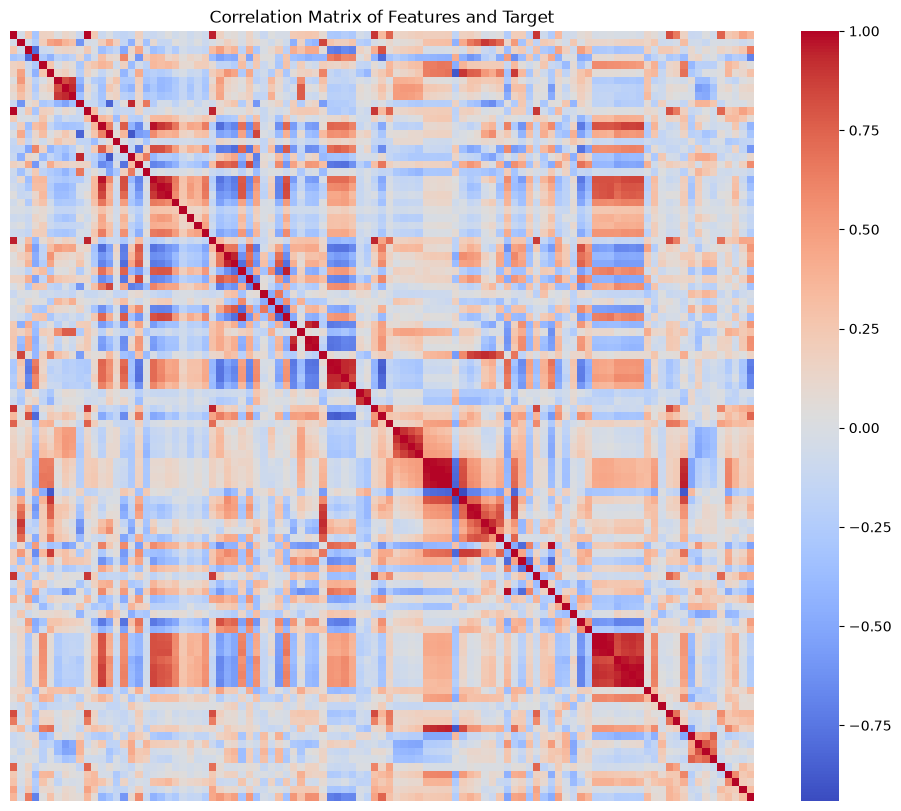

In [12]:
corr_matrix = pd.concat([X_train, pd.Series(y_train, name=target_col)], axis=1).corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', cbar=True, xticklabels=False, yticklabels=False)
plt.title("Correlation Matrix of Features and Target")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [14]:
means = X_train.mean()
stds = X_train.std()

cv = (stds / means.replace(0, np.nan)).fillna(0)
cv_sorted = cv.sort_values(ascending=False)

print(cv_sorted)

NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
                         ...   
PersPerFam             0.317375
PctSameState85         0.298434
agePct12t29            0.291315
PctSpeakEnglOnly       0.289999
PctHousOccup           0.268182
Length: 100, dtype: float64


### (e) Scatter plots and box plots for highest CV features

Top 11 features: ['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


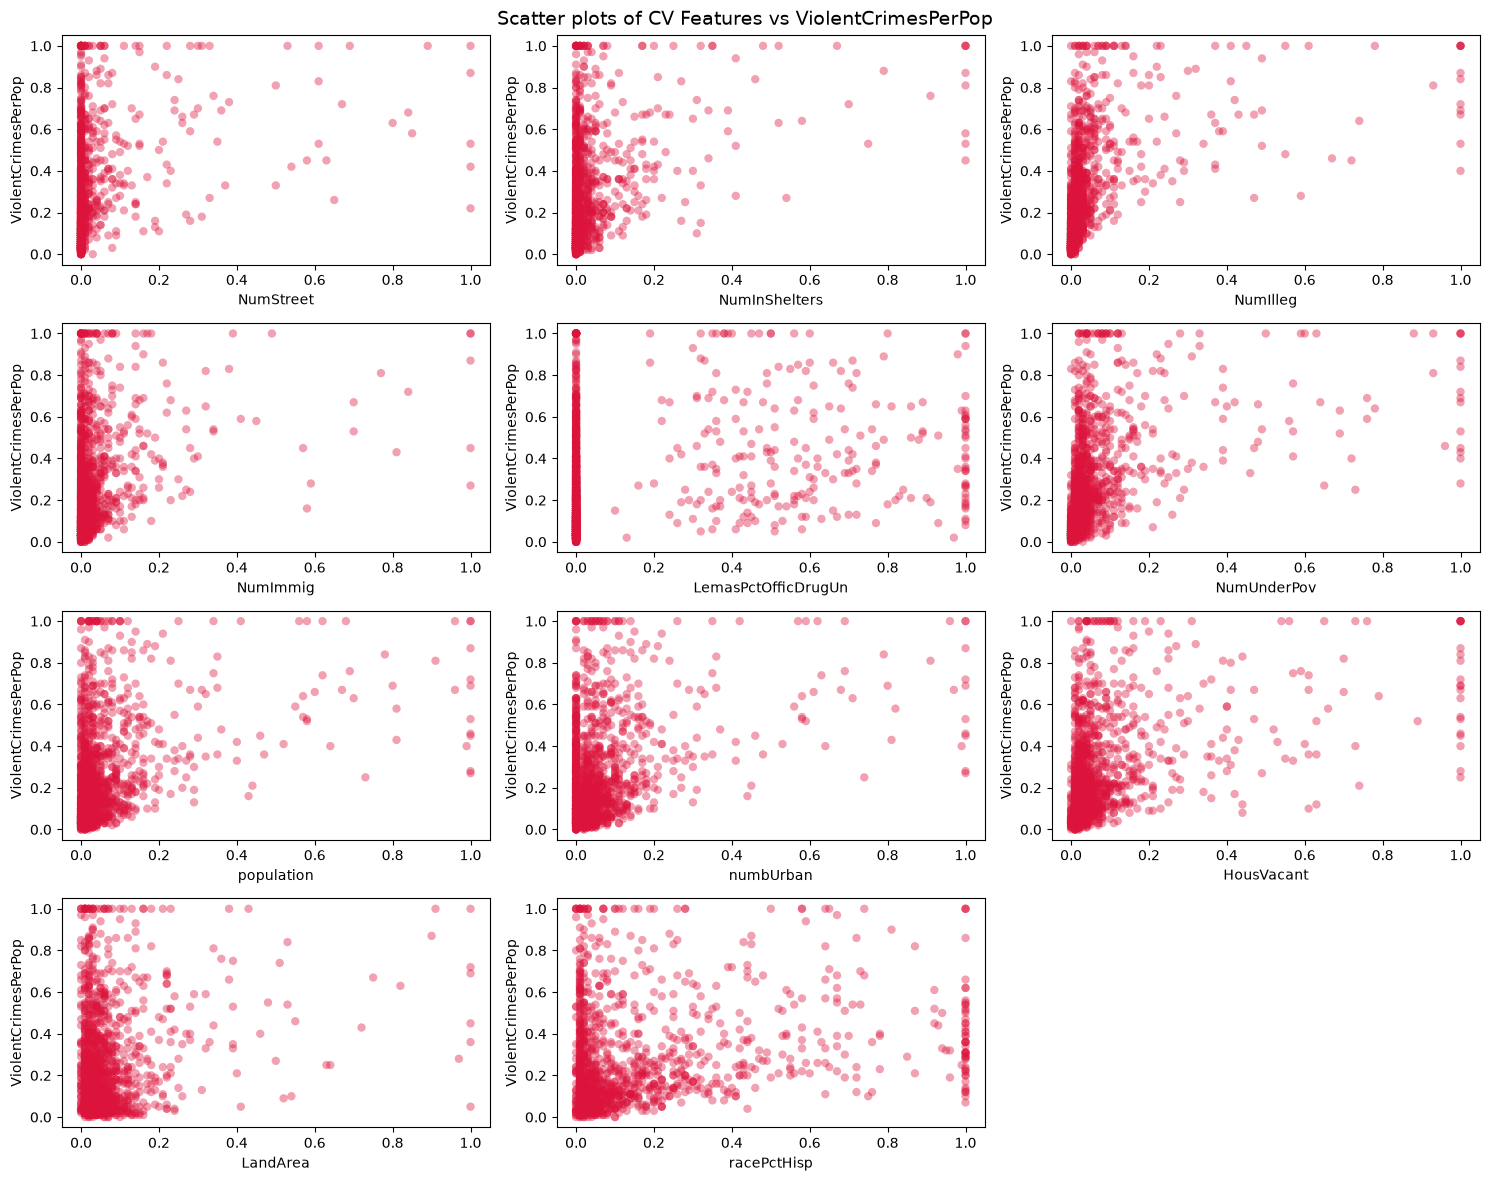

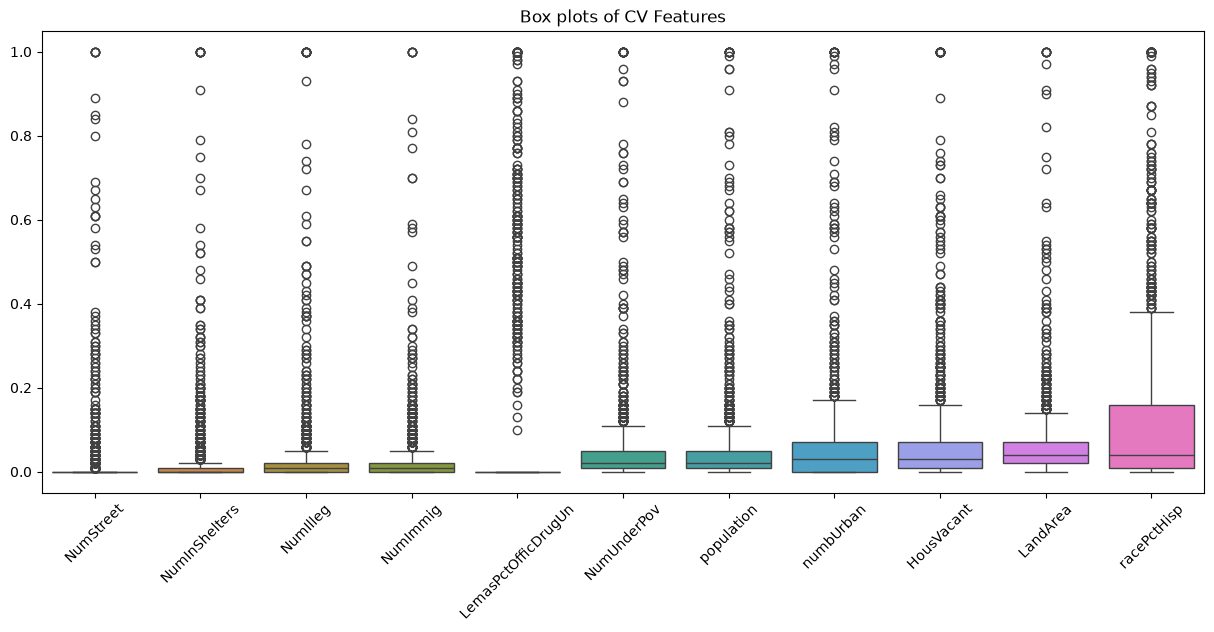

In [20]:
k = int(np.floor(np.sqrt(128)))
top_features = cv_sorted.index[:k].tolist()
print(f"Top {k} features: {top_features}")
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(top_features):
    axes[i].scatter(X_train[col], y_train, alpha=0.4, edgecolors='none', color='crimson')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel(target_col)

for j in range(k, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(f"Scatter plots of CV Features vs {target_col}", fontsize=14)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 6))
sns.boxplot(data=X_train[top_features], orient='v')
plt.xticks(rotation=45)
plt.title(f"Box plots of CV Features")
plt.show()

### (f) Fit a linear model

In [29]:
ols = LinearRegression()
ols.fit(X_train, y_train)

y_pred_ols = ols.predict(X_test)
mse_ols = mean_squared_error(y_test, y_pred_ols)
print(f"Linear Regression Test MSE: {mse_ols:.6f}")

Linear Regression Test MSE: 0.017845


### (g) Fit a ridge regression model

In [28]:
alphas = np.logspace(-4, 4, 200)
ridge_cv = RidgeCV(alphas=alphas, cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train, y_train)

y_pred_ridge = ridge_cv.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)

print(f"Optimal Ridge alpha: {ridge_cv.alpha_:.6f}")
print(f"Ridge Regression Test MSE: {mse_ridge:.6f}")

Optimal Ridge alpha: 1.382622
Ridge Regression Test MSE: 0.017468


### (h) Fit a LASSO model

In [27]:
lasso_cv_raw = LassoCV(alphas=np.logspace(-5, 1, 200), cv=5, max_iter=10000, random_state=42)
lasso_cv_raw.fit(X_train, y_train)

y_pred_lasso_raw = lasso_cv_raw.predict(X_test)
mse_lasso_raw = mean_squared_error(y_test, y_pred_lasso_raw)
selected_vars_raw = X_train.columns[lasso_cv_raw.coef_ != 0].tolist()

print("LASSO Raw")
print(f"Optimal lambda: {lasso_cv_raw.alpha_:.6f}")
print(f"Selected Variables ({len(selected_vars_raw)}): {selected_vars_raw}")
print(f"Test MSE: {mse_lasso_raw:.6f}\n")

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

lasso_cv_std = LassoCV(alphas=np.logspace(-5, 1, 200), cv=5, max_iter=10000, random_state=42)
lasso_cv_std.fit(X_train_std, y_train)

y_pred_lasso_std = lasso_cv_std.predict(X_test_std)
mse_lasso_std = mean_squared_error(y_test, y_pred_lasso_std)
selected_vars_std = X_train.columns[lasso_cv_std.coef_ != 0].tolist()

print("LASSO Standardized")
print(f"Optimal lambda: {lasso_cv_std.alpha_:.6f}")
print(f"Selected Variables ({len(selected_vars_std)}): {selected_vars_std}")
print(f"Test MSE: {mse_lasso_std:.6f}")

LASSO Raw
Optimal lambda: 0.000114
Selected Variables (67): ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'numbUrban', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 

Standardized feature LASSO has a alightly lower Test MSE

### (i) Fit a PCR model

In [30]:
n_components = np.arange(1, X_train.shape[1] + 1)
cv_scores = []

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for M in n_components:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=M)),
        ('linear', LinearRegression())
    ])
    score = -np.mean(cross_val_score(pipe, X_train, y_train, cv=kf, scoring='neg_mean_squared_error'))
    cv_scores.append(score)

best_M = n_components[np.argmin(cv_scores)]

best_pcr = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=best_M)),
    ('linear', LinearRegression())
])
best_pcr.fit(X_train, y_train)
y_pred_pcr = best_pcr.predict(X_test)
mse_pcr = mean_squared_error(y_test, y_pred_pcr)

print(f"Optimal M: {best_M}")
print(f"PCR Test MSE: {mse_pcr:.5f}")

Optimal M: 76
PCR Test MSE: 0.01818


### (j) Fit a boosting tree

In [31]:
param_grid = {
    'reg_alpha': [0, 0.001, 0.01, 0.1, 1, 5, 10]
}

xgb_model = xgb.XGBRegressor(
    n_estimators=150, 
    learning_rate=0.05, 
    max_depth=3, 
    random_state=42, 
    objective='reg:squarederror'
)

xgb_cv = GridSearchCV(
    estimator=xgb_model, 
    param_grid=param_grid, 
    cv=5, 
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
xgb_cv.fit(X_train, y_train)

best_xgb = xgb_cv.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)

print(f"Optimal reg_alpha: {xgb_cv.best_params_['reg_alpha']}")
print(f"L1-regularized XGBoost Test MSE: {mse_xgb:.5f}")

Optimal reg_alpha: 0.001
L1-regularized XGBoost Test MSE: 0.01622
